# Spatial working memory for navigation (Section IV-B, Fig. 4)

**Aim.** ODR showed that a ring of bistable neurons with an RF gate holds a cue, and that a negative pulse erases it. Here the same ring is used to **act**: a target (called an *apple* in the code; the task started as a snake game) is shown once, and the agent walks to it from memory. We ask two things:
1. Does the memory steer the agent? (apples eaten)
2. What does it cost? (spikes per apple, apples per 10,000 spikes)

**Files in this folder**
- `neuron_model.py`: the neurons; the same file as in ODR.
- `network.py`: ring, cue, decision neurons, counters.
- `board.py`: the 10 × 10 board.
- `navigation.py`: the task, the experiments, the tables and the figures.
- `results/`: `runs.csv` (one row per run, every metric), `tables/`, figures.

**The task.**
- A 10 × 10 board, one agent, one apple at a time.
- Each apple is shown once: a forget window (300 ms), then the cue (100 ms).
- The agent then walks from memory, one step per 200 ms.
- The apple is eaten if the agent reaches it. It is lost if no decision neuron fires, the counters are used up on the wrong side, or the agent hits a wall.
- A run = 30 apples; 10 runs (seeds 0–9) per condition.

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image

import navigation as F

torch.set_num_threads(1)
OUT = F.OUT_DIR
os.makedirs(OUT, exist_ok=True)
N_PROC = max(1, (os.cpu_count() or 2) - 2)    # processes for the experiments
SEEDS = range(10)
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 30)

def save(fig, name, dpi=120):
    fig.savefig(os.path.join(OUT, name), dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## LIF settings (change them here)

The LIF is the MNIST / N-MNIST LIF: v ← β·v + I, a spike when v > threshold, then v = 0. The defaults below are the MNIST values plus four numbers set by stated rules.

| setting | default | what it does | less excitable |
|---|---|---|---|
| `beta` | 0.5 | voltage kept per ms (MNIST) | lower |
| `threshold` | 1.0 | spike threshold (MNIST) | higher |
| `cue_w` | 0.4 | LIF ring: current per cue spike. Rule: as many spikes in the cue window as the bistable ring (bistable: 0.084) | lower |
| `ring_gain` | 1.0 | LIF ring: factor on the E → E weights | lower |
| `g_de` | 40 | LIF decision: ring → decision gain. Rule: one ring spike 45° off fires the decision neuron | lower |
| `g_dd` | 3 | LIF decision: inhibition between decision neurons | – |
| `tonic` | 0.015 | LIF decision: a small steady drive (bistable: 0.05) | lower |

Runs of a network with LIF neurons are stored with their LIF settings. New settings start new runs; the old ones stay in `runs.csv`. The all-bistable runs are shared.

In [2]:
LIF = dict(F.LIF_DEFAULT)
# LIF.update(threshold=1.2)      # e.g. a less excitable LIF
print("LIF settings:", F.lif_tag(LIF))

LIF settings: beta0.5_th1_cue0.4_gain1_gde40_gdd3_tonic0.015


## 1. The network

- **Ring (16 E).** Neighbours excite each other (Mexican hat). The cue starts a bump. After the cue, w0 = −1 is kept only in the **RF** (±42.5° around where the bump formed); there the bump keeps firing. This is the memory.
- **Apple cue.** Spikes onto the ring at the apple's compass angle. Shown once, for 100 ms.
- **Decision neurons (E, N, W, S).** Each reads the ring within 90° of its direction. They inhibit each other. The one with most spikes in 200 ms is the step.
- **Counters (distance meters).** See below.

### The counters, in words
A counter is one neuron that **only adds up**. It has no leak, so it never forgets what it has received. There are two: one for the E/W axis and one for the N/S axis.

Take an apple **3 cells east and 2 cells north**.
1. **At the look**, the board gives the counters two numbers: 3 (cells across) and 2 (cells up or down). Each counter's voltage is set below threshold by exactly that many "kicks": E/W starts at 0.375, N/S at 0.625 (rule: v = 1 − (n − 0.5) × 0.25).
2. **Every step along an axis kicks that axis's counter by +0.25.** After 3 steps east or west, the E/W counter crosses threshold (0.375 + 3 × 0.25 = 1.125).
3. **Then it fires, and keeps firing.** It excites itself, so it does not stop.
4. **While it fires, it inhibits both E and W.** The agent can no longer move across, only up or down. The N/S counter does the same after 2 steps north or south.
5. **When both counters fire, the route is done.** If the apple is not there, it was on the other side.

**What the counters do not know is the direction.** They block E *and* W together, because they do not know which of the two is right. East or west, north or south: that comes only from the bump in the ring. If the ring forgets, nothing else tells the agent which way to go.

The counters are the explicit, non-neural part of the model. The board sets them, and every step kicks them. We say this plainly; the claim is about holding the direction.

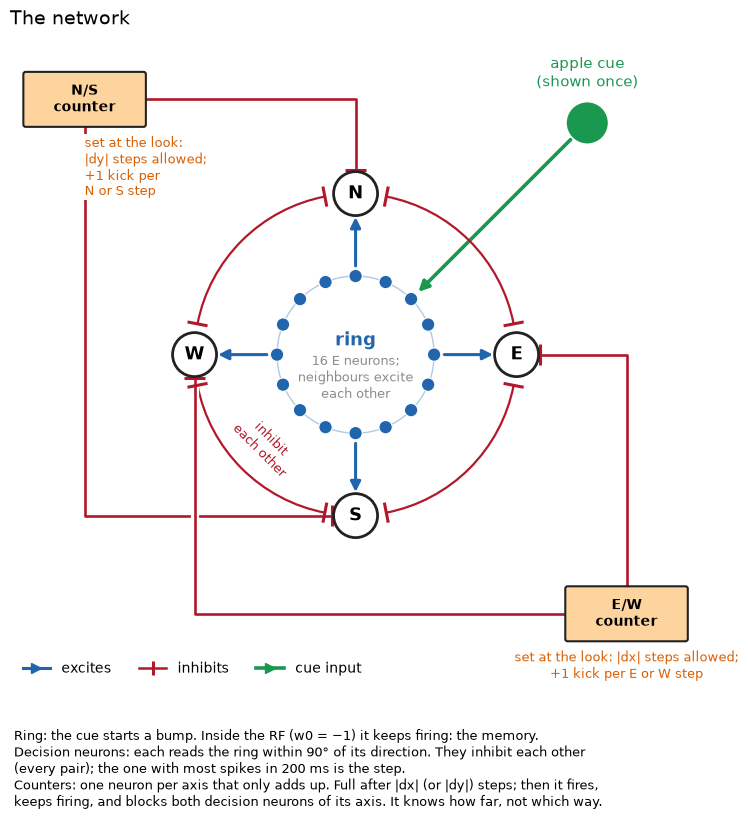

In [3]:
save(F.plot_architecture(), "architecture.png", dpi=130)

## 2. One apple

The agent at (6, 2), the apple at (2, 5): 4 cells west, 3 cells north. It is shown once; then the agent walks from memory.

**How to read it (top to bottom, one time axis)**
- **Board:** the route.
- **Input:** the cue spikes (blue), only during the cue.
- **E neuron:** ring spikes. Pale blue = w0 = −1 on every neuron during the cue. Blue band = the RF, where w0 = −1 is kept. Green = the apple's direction; dashed = the RF centre.
- **Decision:** spikes of E, N, W, S. The letter on top = the step of that 200 ms slot. Gray = that neuron is blocked by its counter.
- **Counter spikes and counter voltage:** each step kicks the voltage up by 0.25. At threshold the counter fires and keeps firing; its voltage then saw-tooths between 0 and 1.
- **Purple:** the forget window (−3 pulse, w0 = +1).

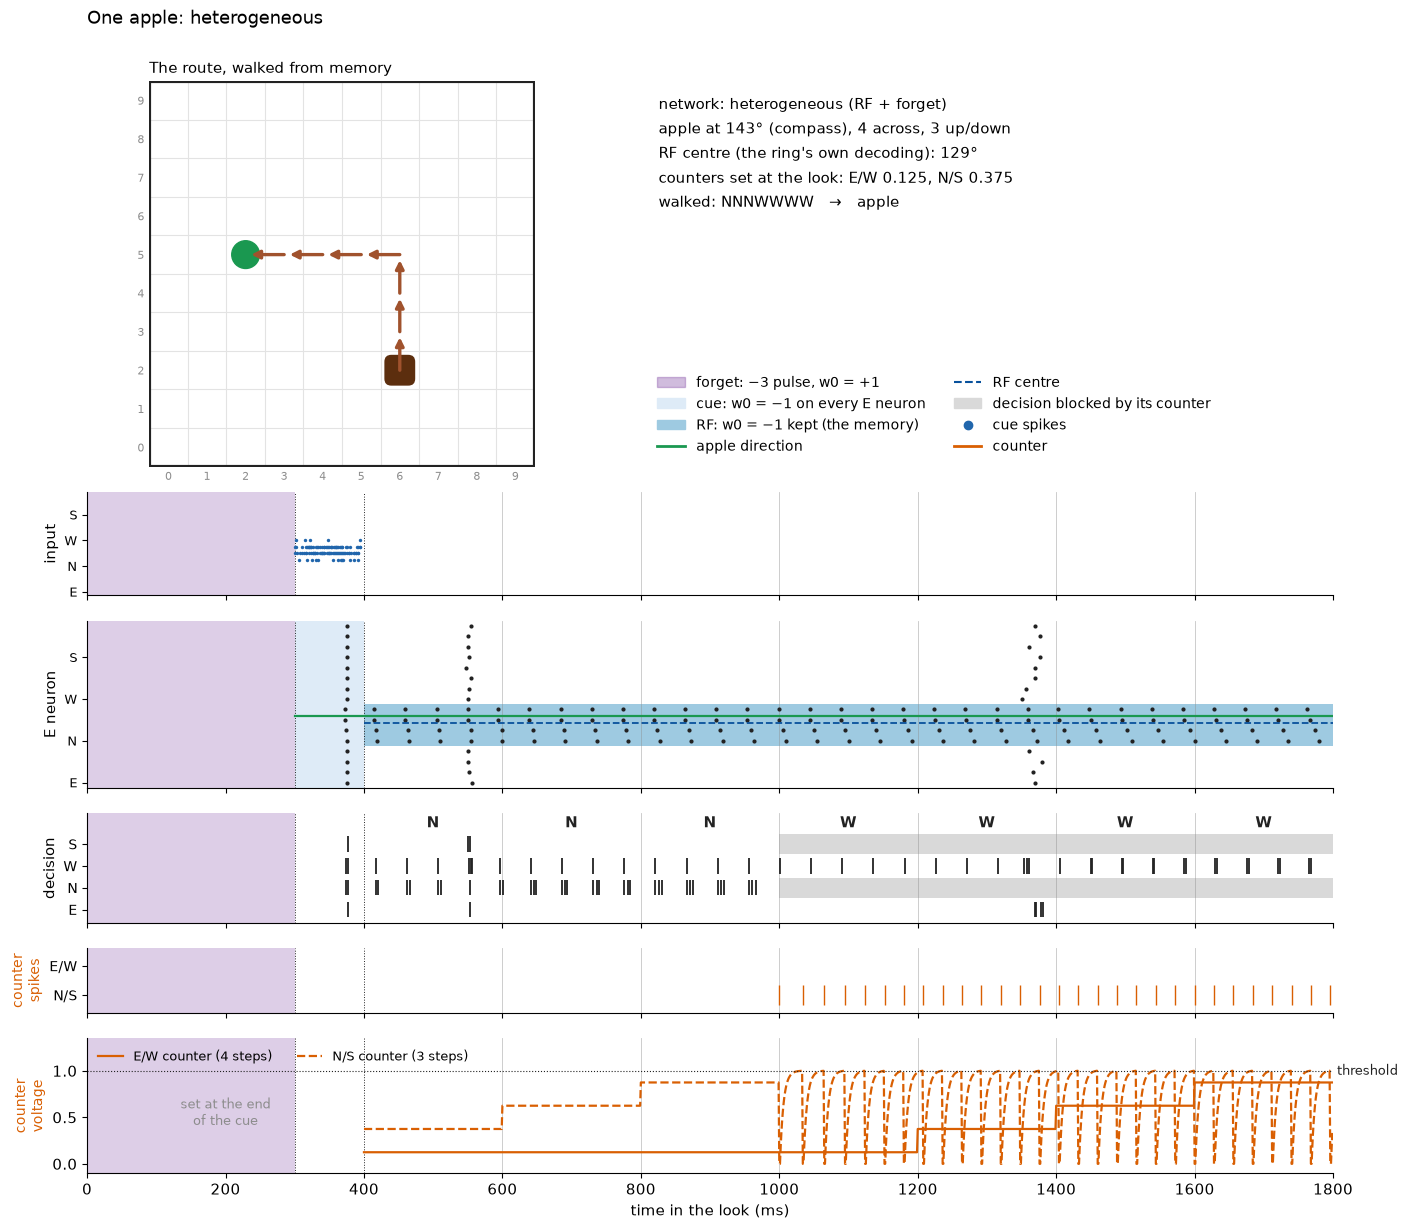

In [4]:
NET = "heterogeneous"                # or "all bistable", "all LIF"
TRIAL = F.run_trial(NET, pos=(6, 2), apple=(2, 5), seed=0, lif=LIF)
save(F.plot_trial(TRIAL), f"one_apple_{NET.replace(' ', '_')}.png")

## 3. Run the experiments

**340 runs of 30 apples** (10 seeds each):
- **A. Comparison:** 3 networks.
- **B. Input noise:** 3 networks × CV 10–50%.
- **C. RF × forget:** 2 bistable-ring networks × 3 conditions (no RF; no forget; neither).
- **D. Weight noise:** 2 bistable-ring networks × CV 10–50%.

CV 0 and "RF + forget" come from A. Each run is appended to `results/runs.csv` as soon as it ends. If the cell stops, run it again: it resumes. About 30–40 minutes with 6 processes. From a terminal instead: `python navigation.py --procs 6` (default LIF settings).

In [5]:
DF = F.run_all(os.path.join(OUT, "runs.csv"), seeds=SEEDS, n_proc=N_PROC, lif=LIF)
T = F.tables(DF, lif=LIF)
print(len(DF), "runs in the file;", {k: len(v) for k, v in T.items()}, "used here")

340 runs to do (0 already in results/runs.csv)
1/340 base | heterogeneous | RF + forget | CV in 0.0 w 0.0 | s1: 30/30 apples, 17 s (total 18 s)
2/340 base | heterogeneous | RF + forget | CV in 0.0 w 0.0 | s2: 28/30 apples, 17 s (total 18 s)
3/340 base | heterogeneous | RF + forget | CV in 0.0 w 0.0 | s0: 30/30 apples, 18 s (total 19 s)
4/340 base | all bistable | RF + forget | CV in 0.0 w 0.0 | s3: 29/30 apples, 26 s (total 27 s)
5/340 base | all bistable | RF + forget | CV in 0.0 w 0.0 | s1: 30/30 apples, 27 s (total 28 s)
6/340 base | all bistable | RF + forget | CV in 0.0 w 0.0 | s8: 25/30 apples, 27 s (total 28 s)
7/340 base | all bistable | RF + forget | CV in 0.0 w 0.0 | s5: 28/30 apples, 27 s (total 28 s)
8/340 base | all bistable | RF + forget | CV in 0.0 w 0.0 | s6: 30/30 apples, 28 s (total 29 s)
9/340 base | all bistable | RF + forget | CV in 0.0 w 0.0 | s2: 27/30 apples, 29 s (total 30 s)
10/340 base | all bistable | RF + forget | CV in 0.0 w 0.0 | s0: 29/30 apples, 29 s (t

**One number for both: apples per 10,000 spikes.**
- It counts only the apples that were eaten, and divides by every spike spent (input + network).
- It falls if fewer apples are eaten, and it falls if more spikes are spent. So it holds both the % eaten and the cost.
- Every other metric is in `runs.csv` and in the tables in `results/tables/`.

## A. Comparison: all bistable, heterogeneous, all LIF

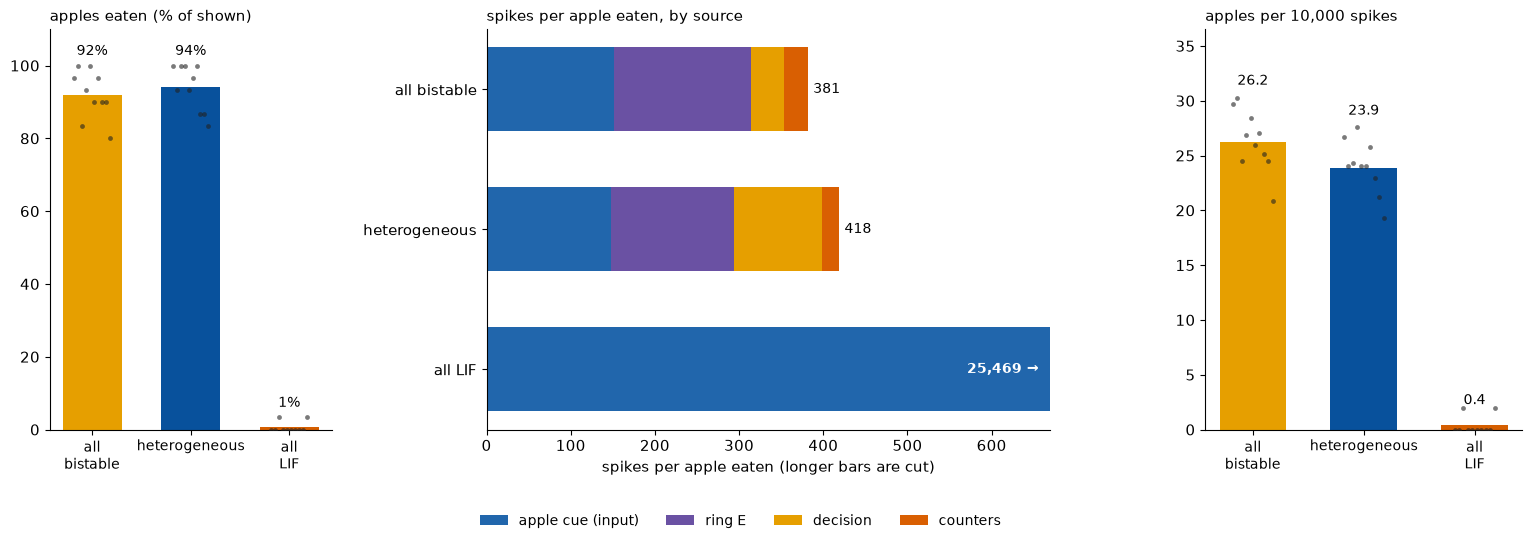

,runs,apples eaten (%),lost: no decision,lost: wrong side,lost: wall,direction error (°),input spikes / apple,ring spikes / apple,decision spikes / apple,counter spikes / apple,all spikes / apple eaten,all spikes / apple shown,apples / 10k spikes
net_type,,,,,,,,,,,,,
all bistable,10,92 ± 7,10,11,3,4.4,152.0,162.0,40.0,28.0,381.0,351.0,26.2
heterogeneous,10,94 ± 6,7,10,1,3.9,148.0,146.0,104.0,20.0,418.0,393.0,23.9
all LIF,10,1 ± 1,298,0,0,2.8,21046.0,1942.0,2020.0,460.0,25469.0,170.0,0.4


In [6]:
save(F.plot_comparison(T["base"]), "A_comparison.png")
F.save_table(F.table(T["base"], "net_type", F.TYPE_ORDER), "A_comparison.csv")

## B. Input noise, CV 0–50%

At every look, the cue rate of each ring neuron is multiplied by its own gain ~ N(1, CV), clipped at 0.

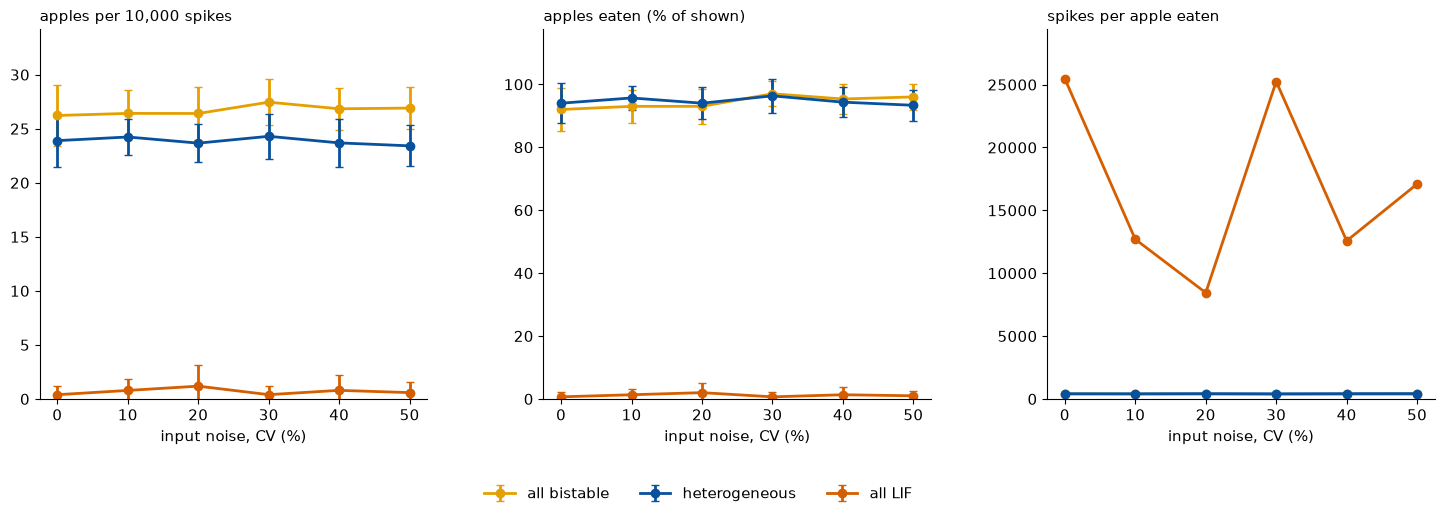

,runs,apples eaten (%),lost: no decision,lost: wrong side,lost: wall,direction error (°),input spikes / apple,ring spikes / apple,decision spikes / apple,counter spikes / apple,all spikes / apple eaten,all spikes / apple shown,apples / 10k spikes
case,,,,,,,,,,,,,
all bistable | CV 0%,10,92 ± 7,10,11,3,4.4,152.0,162.0,40.0,28.0,381.0,351.0,26.2
all bistable | CV 10%,10,93 ± 5,12,8,1,3.8,151.0,161.0,40.0,27.0,379.0,352.0,26.4
all bistable | CV 20%,10,93 ± 6,10,9,2,4.3,150.0,162.0,40.0,27.0,379.0,352.0,26.4
all bistable | CV 30%,10,97 ± 4,4,5,0,4.3,144.0,156.0,38.0,26.0,364.0,353.0,27.5
all bistable | CV 40%,10,95 ± 5,10,3,1,4.9,147.0,160.0,39.0,26.0,373.0,355.0,26.8
all bistable | CV 50%,10,96 ± 4,9,3,0,5.5,146.0,160.0,39.0,26.0,372.0,357.0,26.9
heterogeneous | CV 0%,10,94 ± 6,7,10,1,3.9,148.0,146.0,104.0,20.0,418.0,393.0,23.9
heterogeneous | CV 10%,10,96 ± 4,4,7,2,3.9,147.0,144.0,103.0,19.0,413.0,395.0,24.2
heterogeneous | CV 20%,10,94 ± 5,7,9,2,4.4,149.0,149.0,104.0,20.0,423.0,397.0,23.7


In [7]:
save(F.plot_noise(T["input_noise"], "cv_input", xlabel="input noise, CV (%)"), "B_input_noise.png")
tab = T["input_noise"].assign(case=T["input_noise"]["net_type"] + " | CV "
                              + (100 * T["input_noise"]["cv_input"]).round().astype(int).astype(str) + "%")
F.save_table(F.table(tab, "case", [f"{t} | CV {c}%" for t in F.TYPE_ORDER for c in (0, 10, 20, 30, 40, 50)]),
             "B_input_noise.csv")

## C. RF × forget (bistable rings)

| condition | after the cue | before each look |
|---|---|---|
| **RF + forget** | w0 = −1 only in the RF (±42.5°), 0 elsewhere | forget: −3 pulse, w0 = +1, 300 ms |
| **no RF** | w0 = −1 on the whole ring | forget |
| **no forget** | w0 = −1 only in the RF | a plain 300 ms wait: w0 stays −1, no pulse |
| **no RF, no forget** | w0 = −1 on the whole ring | a plain wait |

Without forget, the last bump is still there at the next look. The first apple of a run has nothing to forget.

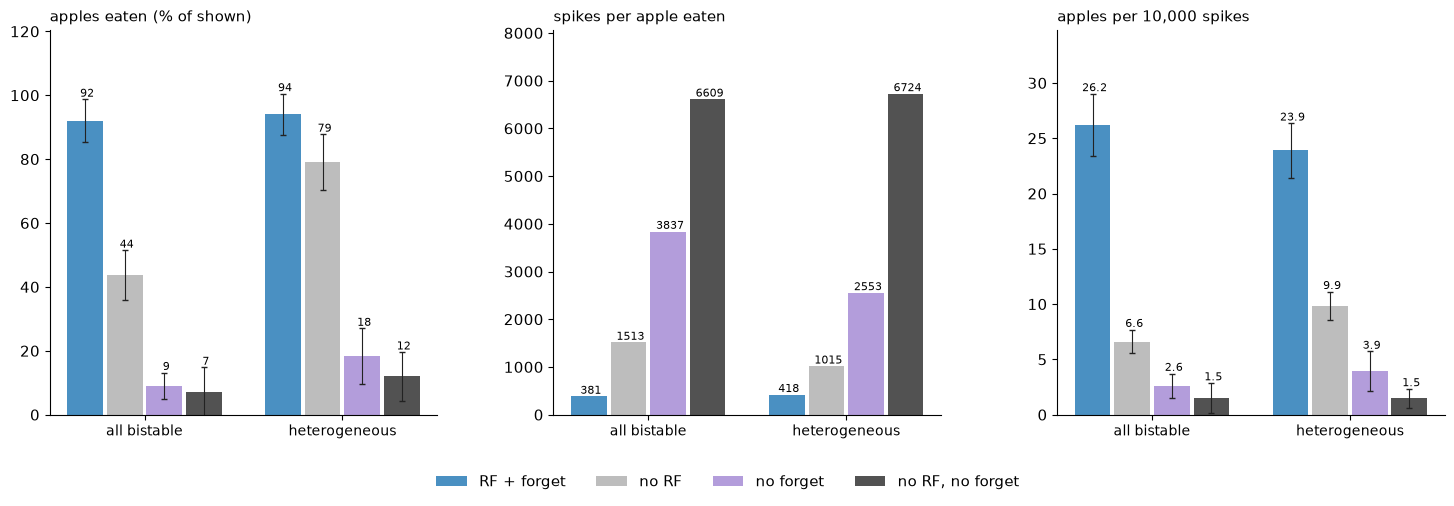

runs apples eaten (%)  lost: no decision  lost: wrong side  lost: wall  direction error (°)  input spikes / apple  ring spikes / apple  decision spikes / apple  counter spikes / apple  \
net_type      condition                                                                                                                                                                                                   
heterogeneous RF + forget         10           94 ± 6                  7                10           1                  3.9                 148.0                146.0                    104.0                    20.0   
all bistable  RF + forget         10           92 ± 7                 10                11           3                  4.4                 152.0                162.0                     40.0                    28.0   
              no forget           10            9 ± 4                  7                 4         262                 94.9                1547.0               1963.0                    217.0                   109.0   
              no RF               10           44 ± 8                  0               104          65                  3.5                 321.0               1049.0                     97.0                    46.0   
              no RF, no forget    10            7 ± 8                  0                23         256                 84.0                1996.0               4118.0                    340.0                   155.0   
heterogeneous no RF               10           79 ± 9                  0                57           6                  3.5                 177.0                612.0                    203.0                    23.0   
              no forget           10           18 ± 9                  1                30         214                109.5                 759.0               1109.0                    574.0                   112.0   
              no RF, no forget    10           12 ± 8                  0                74         190                 88.3                1163.0               3544.0                   1812.0                   205.0   

                                all spikes / apple eaten  all spikes / apple shown  apples / 10k spikes  
net_type      condition                                                                                  
heterogeneous RF + forget                          418.0                     393.0                 23.9  
all bistable  RF + forget                          381.0                     351.0                 26.2  
              no forget                           3837.0                     345.0                  2.6  
              no RF                               1513.0                     661.0                  6.6  
              no RF, no forget                    6609.0                     463.0                  1.5  
heterogeneous no RF                               1015.0                     802.0                  9.9  
              no forget                           2553.0                     468.0                  3.9  
              no RF, no forget                    6724.0                     807.0                  1.5

In [8]:
save(F.plot_rf_forget(T["rf_forget"]), "C_rf_forget.png")
F.save_table(F.table(T["rf_forget"], ["net_type", "condition"]), "C_rf_forget.csv")

## D. Weight noise, CV 0–50% (bistable rings)

As in MNIST and N-MNIST: every synapse is multiplied by (1 + CV·ξ), ξ ~ N(0, 1), drawn once per run; signs may flip. The synapses are cue → E (one per ring neuron), E → E, E → decision and decision → decision. The counters and the background input are left as they are.

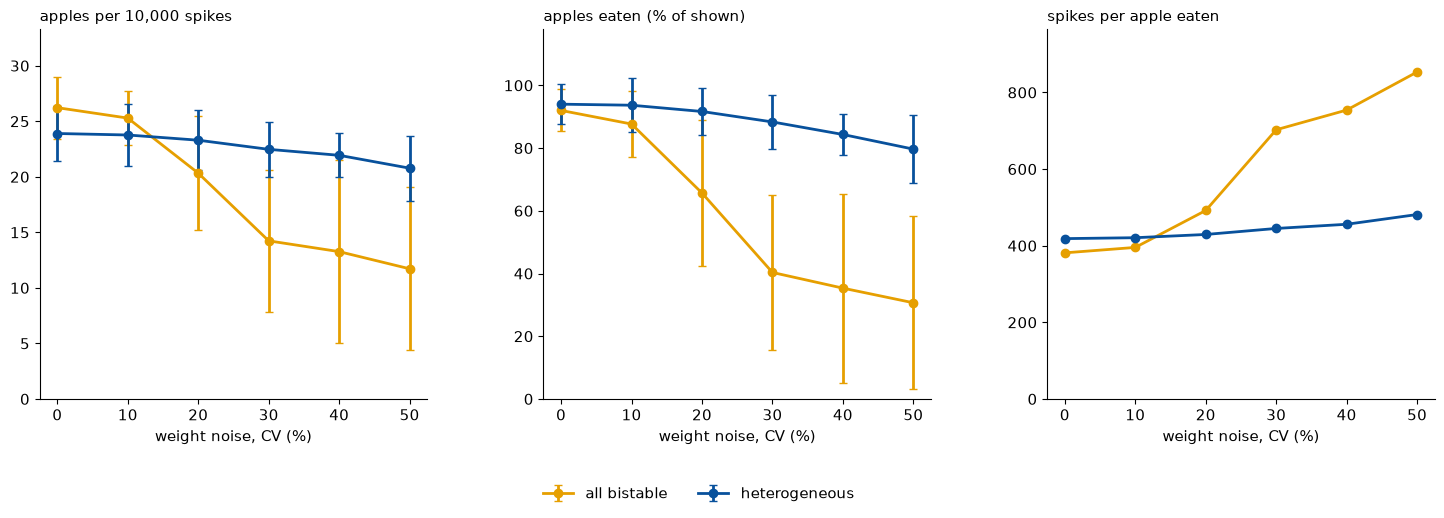

,runs,apples eaten (%),lost: no decision,lost: wrong side,lost: wall,direction error (°),input spikes / apple,ring spikes / apple,decision spikes / apple,counter spikes / apple,all spikes / apple eaten,all spikes / apple shown,apples / 10k spikes
case,,,,,,,,,,,,,
all bistable | CV 0%,10,92 ± 7,10,11,3,4.4,152.0,162.0,40.0,28.0,381.0,351.0,26.2
all bistable | CV 10%,10,88 ± 11,11,19,7,4.2,160.0,166.0,41.0,29.0,396.0,347.0,25.3
all bistable | CV 20%,10,66 ± 23,10,26,67,4.2,215.0,195.0,48.0,34.0,492.0,323.0,20.3
all bistable | CV 30%,10,40 ± 25,11,30,138,4.7,348.0,254.0,60.0,41.0,703.0,283.0,14.2
all bistable | CV 40%,10,35 ± 30,7,22,165,5.4,397.0,258.0,60.0,39.0,754.0,266.0,13.3
all bistable | CV 50%,10,31 ± 28,5,22,181,5.7,453.0,290.0,68.0,43.0,853.0,262.0,11.7
heterogeneous | CV 0%,10,94 ± 6,7,10,1,3.9,148.0,146.0,104.0,20.0,418.0,393.0,23.9
heterogeneous | CV 10%,10,94 ± 9,4,13,2,3.9,150.0,147.0,105.0,19.0,421.0,394.0,23.8
heterogeneous | CV 20%,10,92 ± 7,12,11,2,4.0,153.0,152.0,104.0,21.0,429.0,394.0,23.3


In [9]:
save(F.plot_noise(T["weight_noise"], "cv_weight", types=F.BISTABLE_RINGS, xlabel="weight noise, CV (%)"),
     "D_weight_noise.png")
tab = T["weight_noise"].assign(case=T["weight_noise"]["net_type"] + " | CV "
                               + (100 * T["weight_noise"]["cv_weight"]).round().astype(int).astype(str) + "%")
F.save_table(F.table(tab, "case", [f"{t} | CV {c}%" for t in F.BISTABLE_RINGS for c in (0, 10, 20, 30, 40, 50)]),
             "D_weight_noise.csv")

## Checks
- **Steps into a blocked direction:** a decision neuron won although its counter was firing. This should be 0.
- **Why apples were lost:** no decision, wrong side (counters used up), wall, timeout.

In [10]:
DF[DF.lif_tag.isin(["-", F.lif_tag(LIF)])].groupby(["exp", "net_type", "condition", "cv_input", "cv_weight"]).agg(
    apples=("apples", "sum"), shown=("apples_shown", "sum"), no_decision=("ends_memory", "sum"),
    wrong_side=("ends_route_done", "sum"), wall=("ends_wall", "sum"), timeout=("ends_timeout", "sum"),
    blocked_steps=("closed_steps", "sum"), direction_error=("rf_err_deg", "mean"),
    apples_per_10k=("apples_per_10k", "mean")).round(1)

apples  shown  no_decision  wrong_side  wall  timeout  blocked_steps  direction_error  apples_per_10k
exp          net_type      condition        cv_input cv_weight                                                                                                       
base         all LIF       RF + forget      0.0      0.0             2    300          298           0     0        0              0              2.8             0.4
             all bistable  RF + forget      0.0      0.0           276    300           10          11     3        0              0              4.4            26.3
             heterogeneous RF + forget      0.0      0.0           282    300            7          10     1        0              1              3.9            24.0
input_noise  all LIF       RF + forget      0.1      0.0             4    300          296           0     0        0              0              2.9             0.8
                                            0.2      0.0             6    300          294           0     0        0              0              3.4             1.2
                                            0.3      0.0             2    300          298           0     0        0              0              4.8             0.4
                                            0.4      0.0             4    300          296           0     0        0              0              6.1             0.8
                                            0.5      0.0             3    300          297           0     0        0              0              8.6             0.6
             all bistable  RF + forget      0.1      0.0           279    300           12           8     1        0              0              3.8            26.5
                                            0.2      0.0           279    300           10           9     2        0              0              4.3            26.5
                                            0.3      0.0           291    300            4           5     0        0              0              4.3            27.5
                                            0.4      0.0           286    300           10           3     1        0              0              4.9            26.9
                                            0.5      0.0           288    300            9           3     0        0              0              5.5            27.0
             heterogeneous RF + forget      0.1      0.0           287    300            4           7     2        0              1              3.9            24.3
                                            0.2      0.0           282    300            7           9     2        0              0              4.4            23.7
                                            0.3      0.0           289    300            3           8     0        0              1              4.5            24.4
                                            0.4      0.0           283    300            7           9     1        0              0              5.0            23.8
                                            0.5      0.0           280    300            7          10     3        0              0              5.4            23.5
rf_forget    all bistable  no RF            0.0      0.0           131    300            0         104    65        0              0              3.5             6.6
                           no RF, no forget 0.0      0.0            21    300            0          23   256        0              0             84.0             1.3
                           no forget        0.0      0.0            27    300            7           4   262        0              0             94.9             2.6
             heterogeneous no RF            0.0      0.0           237    300            0          57     6        0              0              3.5             9.9
                           no RF, no forget 0.0      0.0            36    300   

## Optional: a movie of 30 apples, the three networks side by side

Set `MAKE_MOVIE = True`. Filled apple = shown; dashed apple = the agent cannot see it; blue arrow = the direction the ring holds.

In [11]:
MAKE_MOVIE = False
if MAKE_MOVIE:
    RUNS = {t: F.run_one(t, seed=0, lif=LIF)[1] for t in F.TYPE_ORDER}
    path = os.path.join(OUT, "movie_30_apples.gif")
    F.animate_runs(RUNS, path, fps=4)
    display(Image(filename=path))

## Summary (as in the paper, Fig. 4; mean ± s.d. over 10 runs)

- **Targets per 10,000 spikes:** all bistable 26.3 ± 2.8, heterogeneous (bistable ring, LIF decision neurons) 24.0 ± 2.5, all LIF 0.4 ± 0.8. The LIF ring cannot hold the cue.
- **Weight noise:** at a CV of 50 %, the all-bistable network falls by 16, the heterogeneous one by 3. Bistable decision neurons latch; LIF decision neurons do not.
- **RF and forgetting:** removing either drops both networks to 10 or below.

The figure of the paper is drawn by `../NICE_figures/fig4_navigation.ipynb` from `results/runs.csv`.